# Tópico 5 - Resolução Espectral

## Visão Geral e Objetivos
Neste notebook, investigamos o conceito de **Resolução Espectral ($\Delta f$)** na análise de Fourier via DFT/FFT. Os objetivos principais são:
1. **Definição da Resolução Espectral**: Compreender que a separação entre bins de frequência consecutivos é dada por $\Delta f = \frac{f_s}{N} = \frac{1}{T_{obs}}$, onde $f_s$ é a frequência de amostragem e $T_{obs} = N \cdot T_s$ é o tempo total de observação do sinal.
2. **Separação de Componentes Próximas**: Gerar um sinal composto por duas senoides com frequências muito próximas ($f_1 = 100$ Hz e $f_2 = 105$ Hz, diferença de $\Delta f_{sinal} = 5$ Hz).
3. **Impacto do Tamanho do Registro ($N$)**: Avaliar o espectro para $N = 64$, $N = 256$ e $N = 1024$ amostras sob uma taxa de amostragem fixa de $f_s = 1000$ Hz.
4. **Exportação de Figuras**: Salvar os gráficos comparativos gerados localmente para posterior inclusão no relatório técnico.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Geração do Sinal com Frequências Próximas

Consideramos um sinal contínuo simulado contendo duas componentes senoidais de frequências próximas:
$$x(t) = A_1 \cos(2\pi f_1 t) + A_2 \cos(2\pi f_2 t)$$

Parâmetros adotados:
- Frequência de amostragem: $f_s = 1000\text{ Hz}$
- Componente 1: $f_1 = 100\text{ Hz}$, $A_1 = 1.0$
- Componente 2: $f_2 = 105\text{ Hz}$, $A_2 = 1.0$
- Diferença entre frequências: $\Delta f_{sinal} = f_2 - f_1 = 5\text{ Hz}$

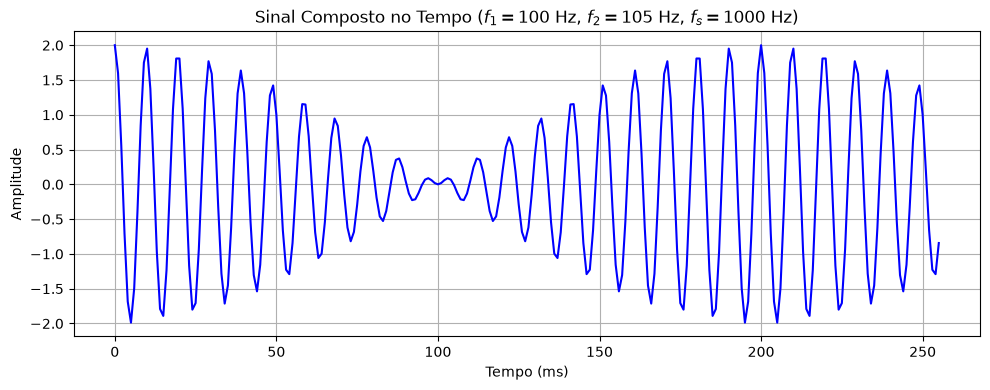

In [2]:
# Parâmetros globais
fs = 1000.0        # Frequência de amostragem em Hz
f1, A1 = 100.0, 1.0  # Primeira frequência (100 Hz)
f2, A2 = 105.0, 1.0  # Segunda frequência (105 Hz)

# Função para gerar o sinal Amostrado para N pontos
def gerar_sinal(N, fs, f1, A1, f2, A2):
    t = np.arange(N) / fs
    x = A1 * np.cos(2 * np.pi * f1 * t) + A2 * np.cos(2 * np.pi * f2 * t)
    return t, x

# Exemplo de visualização no tempo para N = 256
t_256, x_256 = gerar_sinal(256, fs, f1, A1, f2, A2)

fig1, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(t_256 * 1000, x_256, 'b-', linewidth=1.5)
ax1.set_title(r'Sinal Composto no Tempo ($f_1 = 100\text{ Hz}$, $f_2 = 105\text{ Hz}$, $f_s = 1000\text{ Hz}$)')
ax1.set_xlabel('Tempo (ms)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)

plt.tight_layout()
fig1.savefig("grafico_sinal_tempo_resolucao.png")
plt.show()

## 2. Análise da Resolução Espectral para Diferentes Tamanhos de $N$

A resolução espectral teórica é dada por $\Delta f = \frac{f_s}{N}$:
- **Caso 1 ($N = 64$)**: $\Delta f = \frac{1000}{64} = 15.625\text{ Hz}$. Como $\Delta f > 5\text{ Hz}$, a resolução é insuficiente para separar as duas frequências (ambas mesclam-se em um único pico).
- **Caso 2 ($N = 256$)**: $\Delta f = \frac{1000}{256} \approx 3.906\text{ Hz}$. Como $\Delta f < 5\text{ Hz}$, as componentes começam a ser discriminadas no espectro.
- **Caso 3 ($N = 1024$)**: $\Delta f = \frac{1000}{1024} \approx 0.976\text{ Hz}$. Com alta resolução ($\Delta f \ll 5\text{ Hz}$), observam-se dois picos nítidos e perfeitamente isolados nas frequências de $100\text{ Hz}$ e $105\text{ Hz}$.

In [3]:
# Lista de tamanhos de janela de amostragem N
tamanhos_N = 

fig2, axs = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for idx, N in enumerate(tamanhos_N):
    t, x = gerar_sinal(N, fs, f1, A1, f2, A2)
    
    # Cálculo da FFT e eixos de frequência em Hz
    X_fft = np.fft.fft(x)
    freqs = np.fft.fftfreq(N, d=1/fs)
    
    # Tomar apenas a metade positiva do espectro
    metade = N // 2
    freqs_pos = freqs[:metade]
    magnitude = (2.0 / N) * np.abs(X_fft[:metade])
    
    delta_f = fs / N
    T_obs = N / fs
    
    # Plotagem do espectro de magnitude
    axs[idx].plot(freqs_pos, magnitude, 'b-', linewidth=1.8, marker='o', markersize=3)
    axs[idx].set_title(f'N = {N} | $\\Delta f = {delta_f:.3f}\\text{{ Hz}}$ | Tempo de Observação $T_{{obs}} = {T_obs*1000:.1f}\\text{{ ms}}$')
    axs[idx].set_ylabel('Amplitude Normalizada')
    axs[idx].set_xlim(50, 150)  # Zoom na região de interesse em torno de 100 Hz e 105 Hz
    axs[idx].grid(True)
    
    # Demarcar as frequências reais do sinal (100 Hz e 105 Hz)
    axs[idx].axvline(x=100.0, color='r', linestyle='--', alpha=0.7, label='$f_1 = 100\\text{ Hz}$')
    axs[idx].axvline(x=105.0, color='g', linestyle='--', alpha=0.7, label='$f_2 = 105\\text{ Hz}$')
    axs[idx].legend(loc='upper right')

axs[-1].set_xlabel('Frequência (Hz)')
plt.tight_layout()
fig2.savefig("grafico_resolucao_espectral.png")
plt.show()

SyntaxError: invalid syntax (2064939775.py, line 2)

## 3. Síntese dos Resultados sobre Resolução Espectral
- **Impacto de $N$ na Resolução**: Aumentar o número de amostras $N$ sob uma mesma frequência de amostragem $f_s$ estende a janela de observação temporal $T_{obs} = N / f_s$, resultando em um espaçamento menor entre bins discretos ($\Delta f = 1/T_{obs}$).
- **Critério de Separação de Frequências**: Para discriminar duas componentes senoidais separadas por $\Delta f_{sinal}$, é condição necessária que a resolução espectral satisfaça $\Delta f < \Delta f_{sinal}$.
- **Conclusão Prática**: O ganho em resolução espectral não depende apenas do número computacional de pontos da FFT, mas fundamentalmente da **duração total do registro temporal de dados observados**.